# Real-Time Fraud Anomaly Detection

This notebook explores a highly imbalanced credit-card transaction dataset, trains and compares Logistic Regression, Random Forest, and XGBoost, tunes a fraud decision threshold on validation data, evaluates the selected model, and saves reusable prediction artifacts.

**Target:** `Class` (`0` = legitimate, `1` = fraudulent).  
**Important:** This notebook demonstrates offline model inference on transaction records; it is not connected to a live payment stream.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)

print("\nAll libraries are ready!")

Pandas: 2.3.3
NumPy: 2.3.5
Scikit-learn: 1.7.2
XGBoost: 3.4.1

All libraries are ready!


In [2]:
import pandas as pd
import numpy as np

# Load the dataset
df = pd.read_csv("creditcard.csv")

# Display first 5 rows
display(df.head())


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sum())

Dataset shape: (284807, 31)

Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 

In [4]:
print(df["Class"].value_counts())

print("\nClass percentages:")
print((df["Class"].value_counts(normalize=True) * 100).round(4))

Class
0    284315
1       492
Name: count, dtype: int64

Class percentages:
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64


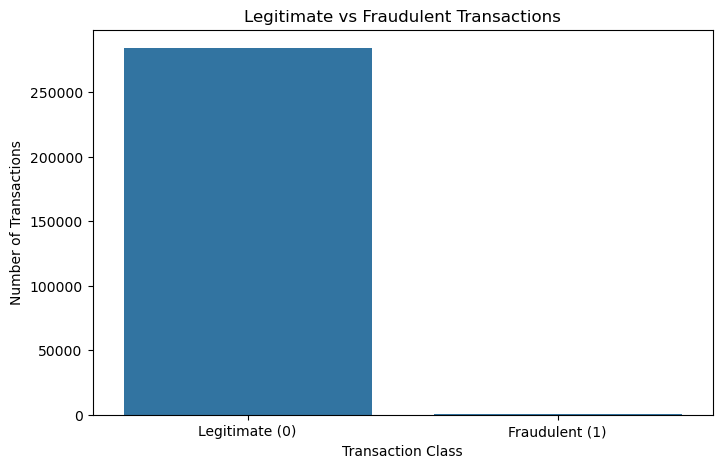

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count transactions in each class
class_counts = df["Class"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
sns.barplot(
    x=["Legitimate (0)", "Fraudulent (1)"],
    y=class_counts.values
)

plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.show()

In [6]:
total_transactions = len(df)
fraud_transactions = (df["Class"] == 1).sum()
legitimate_transactions = (df["Class"] == 0).sum()

print("Total transactions:", total_transactions)
print("Legitimate transactions:", legitimate_transactions)
print("Fraudulent transactions:", fraud_transactions)
print(
    "Fraud percentage:",
    round(fraud_transactions / total_transactions * 100, 4), "%"
)

Total transactions: 284807
Legitimate transactions: 284315
Fraudulent transactions: 492
Fraud percentage: 0.1727 %


In [7]:
# Separate transaction amounts by class
legitimate_amounts = df[df["Class"] == 0]["Amount"]
fraud_amounts = df[df["Class"] == 1]["Amount"]

print("Legitimate transaction amounts:")
print(legitimate_amounts.describe())

print("\nFraudulent transaction amounts:")
print(fraud_amounts.describe())

Legitimate transaction amounts:
count    284315.000000
mean         88.291022
std         250.105092
min           0.000000
25%           5.650000
50%          22.000000
75%          77.050000
max       25691.160000
Name: Amount, dtype: float64

Fraudulent transaction amounts:
count     492.000000
mean      122.211321
std       256.683288
min         0.000000
25%         1.000000
50%         9.250000
75%       105.890000
max      2125.870000
Name: Amount, dtype: float64


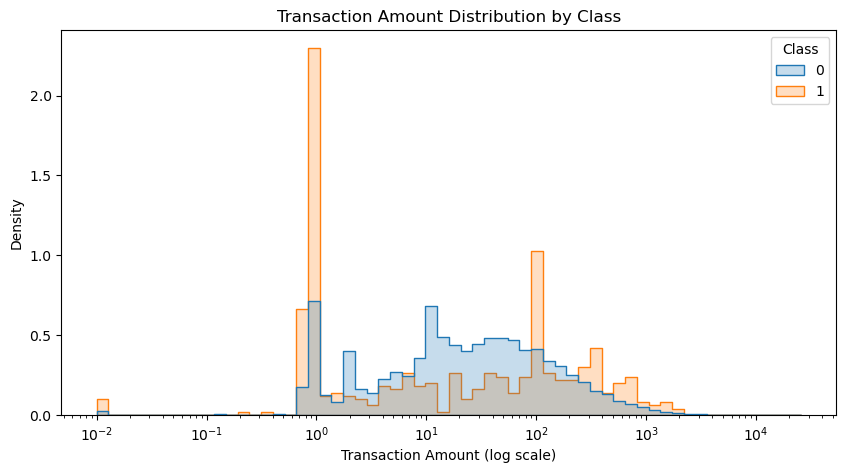

In [8]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df[df["Amount"] > 0],
    x="Amount",
    hue="Class",
    bins=60,
    log_scale=(True, False),
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Transaction Amount Distribution by Class")
plt.xlabel("Transaction Amount (log scale)")
plt.ylabel("Density")
plt.show()

In [9]:
print(
    df.groupby("Class")["Amount"]
      .median()
      .rename(index={0: "Legitimate", 1: "Fraudulent"})
)

Class
Legitimate    22.00
Fraudulent     9.25
Name: Amount, dtype: float64


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate input features and target label
X = df.drop(columns=["Class"])
y = df["Class"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training features: (227845, 30)
Testing features: (56962, 30)

Training class distribution:
Class
0    227451
1       394
Name: count, dtype: int64

Testing class distribution:
Class
0    56864
1       98
Name: count, dtype: int64


In [11]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit on training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data without refitting
X_test_scaled = scaler.transform(X_test)

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)
print("\nFeature scaling completed successfully!")

Scaled training data shape: (227845, 30)
Scaled testing data shape: (56962, 30)

Feature scaling completed successfully!


In [12]:
from sklearn.linear_model import LogisticRegression

# Create the model
lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

# Train using scaled training features
lr_model.fit(X_train_scaled, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [13]:
# Predict transaction classes
y_pred_lr = lr_model.predict(X_test_scaled)

# Predict fraud probabilities
y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated successfully!")
print("First 10 predicted classes:", y_pred_lr[:10])
print("First 10 fraud probabilities:", y_prob_lr[:10].round(4))

Predictions generated successfully!
First 10 predicted classes: [0 0 0 0 1 0 0 0 0 0]
First 10 fraud probabilities: [5.700e-03 6.760e-02 1.000e-04 1.510e-02 9.456e-01 1.320e-02 8.000e-04
 2.700e-02 6.420e-02 4.400e-03]


In [14]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

print("CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=["Legitimate", "Fraudulent"],
    zero_division=0
))

print("PR-AUC:", round(
    average_precision_score(y_test, y_prob_lr), 4
))

print("ROC-AUC:", round(
    roc_auc_score(y_test, y_prob_lr), 4
))

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       1.00      0.98      0.99     56864
  Fraudulent       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962

PR-AUC: 0.719
ROC-AUC: 0.9721


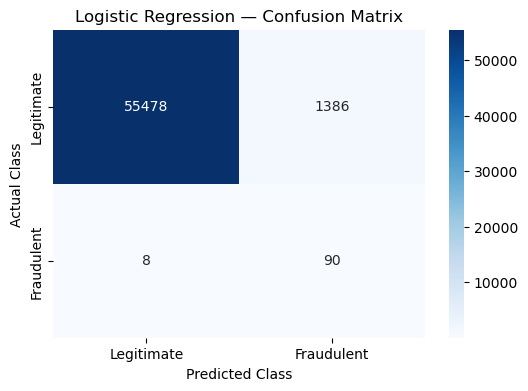

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraudulent"],
    yticklabels=["Legitimate", "Fraudulent"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Logistic Regression — Confusion Matrix")
plt.show()

In [16]:
from sklearn.ensemble import RandomForestClassifier
import time

start_time = time.time()

rf_model = RandomForestClassifier(
    n_estimators=20,
    max_depth=12,
    class_weight="balanced",
    random_state=42,
    n_jobs=2
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")
print("Time taken:", round(time.time() - start_time, 2), "seconds")

Random Forest training completed!
Time taken: 15.62 seconds


In [17]:
# Predict transaction classes on the test dataset
y_pred_rf = rf_model.predict(X_test)

# Predict probability of fraud
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Predictions completed successfully!")
print("First 10 predicted classes:", y_pred_rf[:10])
print("First 10 fraud probabilities:", y_prob_rf[:10].round(4))

Predictions completed successfully!
First 10 predicted classes: [0 0 0 0 0 0 0 0 0 0]
First 10 fraud probabilities: [0.     0.     0.0495 0.     0.0997 0.0037 0.     0.     0.     0.    ]


RANDOM FOREST CLASSIFICATION REPORT

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
  Fraudulent       0.80      0.79      0.79        98

    accuracy                           1.00     56962
   macro avg       0.90      0.89      0.90     56962
weighted avg       1.00      1.00      1.00     56962

PR-AUC: 0.822
ROC-AUC: 0.9581


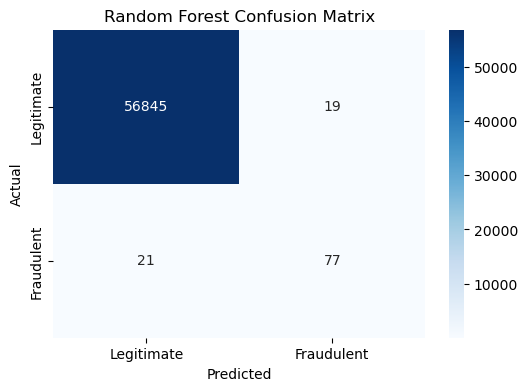

In [18]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)
import matplotlib.pyplot as plt
import seaborn as sns

# Classification metrics
print("RANDOM FOREST CLASSIFICATION REPORT\n")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Legitimate", "Fraudulent"],
    zero_division=0
))

print("PR-AUC:", round(
    average_precision_score(y_test, y_prob_rf), 4
))

print("ROC-AUC:", round(
    roc_auc_score(y_test, y_prob_rf), 4
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraudulent"],
    yticklabels=["Legitimate", "Fraudulent"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.show()

In [19]:
from xgboost import XGBClassifier
import time

# Calculate class imbalance using training labels only
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_weight = negative_count / positive_count

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    scale_pos_weight=scale_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=2
)

start_time = time.time()

xgb_model.fit(X_train, y_train)

print("XGBoost training completed!")
print("Time taken:", round(time.time() - start_time, 2), "seconds")

XGBoost training completed!
Time taken: 2.93 seconds


In [20]:
# Predict transaction classes
y_pred_xgb = xgb_model.predict(X_test)

# Get predicted fraud probabilities
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

print("XGBoost predictions completed!")
print("First 10 predicted classes:", y_pred_xgb[:10])
print("First 10 fraud probabilities:", y_prob_xgb[:10].round(4))

XGBoost predictions completed!
First 10 predicted classes: [0 0 0 0 0 0 0 0 0 0]
First 10 fraud probabilities: [0.0013 0.0014 0.0079 0.0018 0.2409 0.0033 0.0027 0.0036 0.0051 0.0022]


XGBOOST CLASSIFICATION REPORT

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
  Fraudulent       0.35      0.87      0.49        98

    accuracy                           1.00     56962
   macro avg       0.67      0.93      0.75     56962
weighted avg       1.00      1.00      1.00     56962

PR-AUC: 0.8327
ROC-AUC: 0.9811


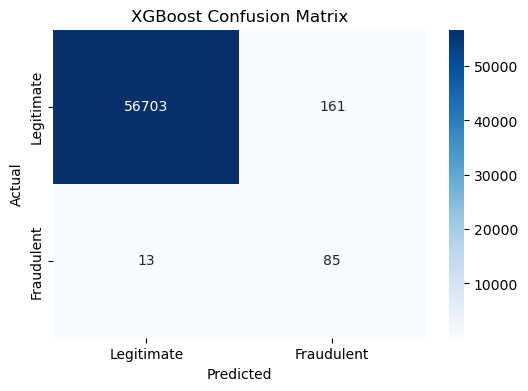

In [21]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)
import matplotlib.pyplot as plt
import seaborn as sns

print("XGBOOST CLASSIFICATION REPORT\n")

print(classification_report(
    y_test,
    y_pred_xgb,
    target_names=["Legitimate", "Fraudulent"],
    zero_division=0
))

print("PR-AUC:", round(
    average_precision_score(y_test, y_prob_xgb), 4
))

print("ROC-AUC:", round(
    roc_auc_score(y_test, y_prob_xgb), 4
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraudulent"],
    yticklabels=["Legitimate", "Fraudulent"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("XGBoost Confusion Matrix")
plt.show()

In [22]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)
import pandas as pd

# Compare model performance
models = {
    "Logistic Regression": (y_pred_lr, y_prob_lr),
    "Random Forest": (y_pred_rf, y_prob_rf),
    "XGBoost": (y_pred_xgb, y_prob_xgb)
}

results = []

for name, (predictions, probabilities) in models.items():
    results.append({
        "Model": name,
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "PR-AUC": average_precision_score(
            y_test, probabilities
        ),
        "ROC-AUC": roc_auc_score(
            y_test, probabilities
        )
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values("PR-AUC", ascending=False)
              .round(4)
              .reset_index(drop=True)
)

,Model,Precision,Recall,F1-Score,PR-AUC,ROC-AUC
0,XGBoost,0.3455,0.8673,0.4942,0.8327,0.9811
1,Random Forest,0.8021,0.7857,0.7938,0.8220,0.9581
2,Logistic Regression,0.0610,0.9184,0.1144,0.7190,0.9721


In [23]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import precision_recall_curve
import numpy as np

# Create a validation set from training data only
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Train Random Forest
rf_tune = RandomForestClassifier(
    n_estimators=20,
    max_depth=12,
    class_weight="balanced",
    random_state=42,
    n_jobs=2
)
rf_tune.fit(X_fit, y_fit)

# Train XGBoost
xgb_tune = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    scale_pos_weight=(y_fit == 0).sum() / (y_fit == 1).sum(),
    eval_metric="logloss",
    random_state=42,
    n_jobs=2
)
xgb_tune.fit(X_fit, y_fit)

# Select a threshold achieving at least 80% validation recall
selected_thresholds = {}
validation_metrics = {}

for name, model in [
    ("Random Forest", rf_tune),
    ("XGBoost", xgb_tune)
]:
    probabilities = model.predict_proba(X_val)[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_val, probabilities
    )

    eligible = np.where(recall[:-1] >= 0.80)[0]

    if len(eligible) == 0:
        print(name, ": No threshold met the recall target.")
        continue

    best_idx = eligible[
        np.argmax(precision[:-1][eligible])
    ]
    threshold = float(thresholds[best_idx])
    selected_thresholds[name] = threshold
    validation_metrics[name] = {
        "precision": float(precision[best_idx]),
        "recall": float(recall[best_idx])
    }

    print(f"\n{name}")
    print("Selected threshold:", round(threshold, 4))
    print("Validation precision:", round(precision[best_idx], 4))
    print("Validation recall:", round(recall[best_idx], 4))


Random Forest
Selected threshold: 0.1907
Validation precision: 0.7033
Validation recall: 0.8101

XGBoost
Selected threshold: 0.8023
Validation precision: 0.7442
Validation recall: 0.8101


TUNED XGBOOST — TEST RESULTS

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
  Fraudulent       0.62      0.85      0.72        98

    accuracy                           1.00     56962
   macro avg       0.81      0.92      0.86     56962
weighted avg       1.00      1.00      1.00     56962

PR-AUC: 0.8228
ROC-AUC: 0.982


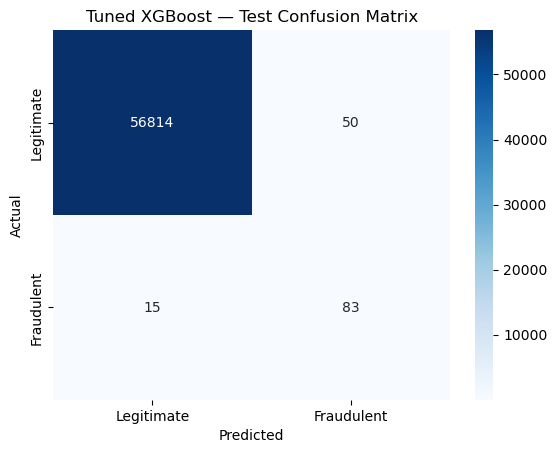

In [24]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)
import matplotlib.pyplot as plt
import seaborn as sns

# Use the tuned XGBoost model and its selected threshold
xgb_threshold = selected_thresholds["XGBoost"]

test_probabilities = xgb_tune.predict_proba(X_test)[:, 1]

test_predictions = (
    test_probabilities >= xgb_threshold
).astype(int)

print("TUNED XGBOOST — TEST RESULTS\n")

print(classification_report(
    y_test,
    test_predictions,
    target_names=["Legitimate", "Fraudulent"],
    zero_division=0
))

print("PR-AUC:", round(
    average_precision_score(y_test, test_probabilities), 4
))

print("ROC-AUC:", round(
    roc_auc_score(y_test, test_probabilities), 4
))

cm = confusion_matrix(y_test, test_predictions)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraudulent"],
    yticklabels=["Legitimate", "Fraudulent"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Tuned XGBoost — Test Confusion Matrix")
plt.show()

In [25]:
import joblib
import os

# Create a folder for saved models
os.makedirs("models", exist_ok=True)

# Save the trained XGBoost model
joblib.dump(
    xgb_tune,
    "models/fraud_xgboost_model.pkl"
)

# Save the selected decision threshold
joblib.dump(
    xgb_threshold,
    "models/fraud_threshold.pkl"
)

print("Model saved successfully!")
print("Model: models/fraud_xgboost_model.pkl")
print("Threshold: models/fraud_threshold.pkl")

Model saved successfully!
Model: models/fraud_xgboost_model.pkl
Threshold: models/fraud_threshold.pkl


In [26]:
import joblib
import numpy as np

# Load the saved model and threshold
loaded_model = joblib.load("models/fraud_xgboost_model.pkl")
loaded_threshold = joblib.load("models/fraud_threshold.pkl")

# Take one transaction from the test dataset
sample_transaction = X_test.iloc[[0]]

# Predict fraud probability
fraud_probability = loaded_model.predict_proba(sample_transaction)[0, 1]

# Apply the saved threshold
prediction = int(fraud_probability >= loaded_threshold)

print("Fraud Probability:", round(fraud_probability * 100, 2), "%")
print("Decision Threshold:", loaded_threshold)

if prediction == 1:
    print("Prediction: POTENTIAL FRAUD")
else:
    print("Prediction: LIKELY LEGITIMATE")

Fraud Probability: 0.13 %
Decision Threshold: 0.8023034930229187
Prediction: LIKELY LEGITIMATE


In [27]:
def predict_fraud(transaction, model=loaded_model, threshold=loaded_threshold):
    """
    Predict whether a transaction is potentially fraudulent.

    transaction: pandas DataFrame containing the same feature
                 columns used during model training.
    """
    probability = model.predict_proba(transaction)[:, 1]
    predictions = (probability >= threshold).astype(int)

    results = transaction.copy()
    results["Fraud_Probability"] = probability.round(4)
    results["Prediction"] = np.where(
        predictions == 1,
        "Potential Fraud",
        "Likely Legitimate"
    )

    return results

In [28]:
sample_result = predict_fraud(X_test.iloc[[0]])
display(sample_result)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Fraud_Probability,Prediction
263020,160760.0,-0.674466,1.408105,-1.110622,-1.328366,1.388996,-1.308439,1.885879,-0.614233,0.311652,...,0.810034,-0.224327,0.707899,-0.135837,0.045102,0.533837,0.291319,23.0,0.0013,Likely Legitimate


In [29]:
# Select 10 transactions from the test dataset
sample_transactions = X_test.iloc[:10]

# Predict all 10 transactions
batch_results = predict_fraud(sample_transactions)

# Display prediction summary
display(
    batch_results[
        ["Fraud_Probability", "Prediction"]
    ]
)

print("\nPrediction Summary:")
print(batch_results["Prediction"].value_counts())

,Fraud_Probability,Prediction
263020,0.0013,Likely Legitimate
11378,0.0018,Likely Legitimate
147283,0.0051,Likely Legitimate
219439,0.0006,Likely Legitimate
36939,0.0751,Likely Legitimate
243438,0.0009,Likely Legitimate
259448,0.0006,Likely Legitimate
43800,0.0019,Likely Legitimate
66742,0.0018,Likely Legitimate
66499,0.0009,Likely Legitimate



Prediction Summary:
Prediction
Likely Legitimate    10
Name: count, dtype: int64


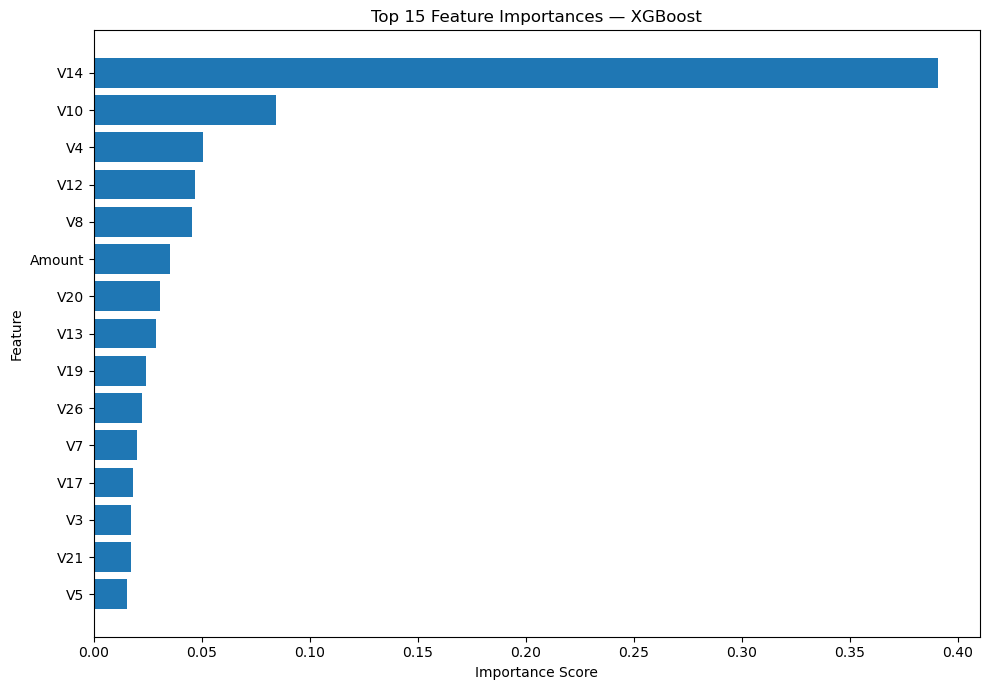

,Feature,Importance
0,V14,0.390812
1,V10,0.084540
2,V4,0.050793
3,V12,0.046966
4,V8,0.045596
5,Amount,0.035512
6,V20,0.030669
7,V13,0.028850
8,V19,0.024246
9,V26,0.022359


In [30]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance from the trained XGBoost model
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": loaded_model.feature_importances_
})

# Select the 15 most important features
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(15)

# Plot feature importance
plt.figure(figsize=(10, 7))
plt.barh(
    importance_df["Feature"][::-1],
    importance_df["Importance"][::-1]
)

plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Top 15 Feature Importances — XGBoost")
plt.tight_layout()
plt.show()

display(importance_df.reset_index(drop=True))

In [31]:
final_comparison = pd.DataFrame({
    "Model": ["XGBoost", "Random Forest", "Logistic Regression"],
    "Precision": [0.3455, 0.8021, 0.0610],
    "Recall": [0.8673, 0.7857, 0.9184],
    "F1-Score": [0.4942, 0.7938, 0.1144],
    "PR-AUC": [0.8327, 0.8220, 0.7190],
    "ROC-AUC": [0.9811, 0.9581, 0.9721]
})

final_comparison = final_comparison.sort_values(
    "PR-AUC", ascending=False
).reset_index(drop=True)

display(final_comparison.round(4))

final_comparison.to_csv("fraud_model_comparison.csv", index=False)

,Model,Precision,Recall,F1-Score,PR-AUC,ROC-AUC
0,XGBoost,0.3455,0.8673,0.4942,0.8327,0.9811
1,Random Forest,0.8021,0.7857,0.7938,0.8220,0.9581
2,Logistic Regression,0.0610,0.9184,0.1144,0.7190,0.9721


# Real-Time Fraud Anomaly Detection

## 1. Project Conclusion

This project developed a machine learning-based credit card fraud detection system using Python and the Credit Card Fraud Detection dataset. Three classification algorithms—Logistic Regression, Random Forest, and XGBoost—were trained and evaluated.

The models were assessed using precision, recall, F1-score, Precision-Recall AUC (PR-AUC), and ROC-AUC. Since fraudulent transactions represent a very small proportion of the dataset, these metrics provide more useful insights than accuracy alone.

XGBoost was selected as the current candidate model after threshold tuning on a validation dataset. At the selected threshold of 0.8023, the model achieved approximately 84.7% fraud recall and 62% fraud precision on the evaluated test set. It detected 83 of 98 fraudulent transactions, while 15 fraudulent transactions were missed.

The trained model and its decision threshold were saved for reuse. A reusable prediction function, batch prediction workflow, and feature-importance visualization were also developed.

## 2. Limitations

- The model was trained on a historical, publicly available dataset and may not generalize to all real-world transactions.
- Fraud patterns can change over time, requiring monitoring and periodic retraining.
- False positives may inconvenience legitimate customers, while false negatives allow some fraudulent transactions to go undetected.
- The current notebook demonstrates model inference but does not connect to a live payment system or streaming transaction source.
- Feature importance indicates model reliance on features, not causal relationships.

## 3. Future Enhancements

- Integrate a live transaction stream or simulated real-time transaction feed.
- Develop a monitoring dashboard for fraud alerts and model performance.
- Evaluate additional approaches, including Isolation Forest and other anomaly detection methods.
- Add model monitoring, drift detection, and periodic retraining.
- Evaluate probability calibration and select thresholds based on operational costs.
- Test the final model on a fresh, independent dataset before real-world deployment.

## 4. Technologies Used

Python, Jupyter Notebook, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, XGBoost, and Joblib.